In [1]:
from google.colab import files
import pandas as pd
import io
uploaded = files.upload()

# Get the filename
filename = list(uploaded.keys())[0]

# Load the CSV into a DataFrame
df = pd.read_csv(io.BytesIO(uploaded[filename]))
display(df.head())

Saving fastfood.csv to fastfood.csv


,restaurant,item,calories,cal_fat,total_fat,sat_fat,trans_fat,cholesterol,sodium,total_carb,fiber,sugar,protein,vit_a,vit_c,calcium,salad
0,Mcdonalds,Artisan Grilled Chicken Sandwich,380,60,7,2.0,0.0,95,1110,44,3.0,11,37.0,4.0,20.0,20.0,Other
1,Mcdonalds,Single Bacon Smokehouse Burger,840,410,45,17.0,1.5,130,1580,62,2.0,18,46.0,6.0,20.0,20.0,Other
2,Mcdonalds,Double Bacon Smokehouse Burger,1130,600,67,27.0,3.0,220,1920,63,3.0,18,70.0,10.0,20.0,50.0,Other
3,Mcdonalds,Grilled Bacon Smokehouse Chicken Sandwich,750,280,31,10.0,0.5,155,1940,62,2.0,18,55.0,6.0,25.0,20.0,Other
4,Mcdonalds,Crispy Bacon Smokehouse Chicken Sandwich,920,410,45,12.0,0.5,120,1980,81,4.0,18,46.0,6.0,20.0,20.0,Other


=== Q1: Highest Menu Count -> Taco Bell (115 items) ===


,Restaurant,Item_Count
0,Taco Bell,115
1,Subway,96
2,Burger King,70
3,Mcdonalds,57
4,Arbys,55
5,Sonic,53
6,Dairy Queen,42
7,Chick Fil-A,27



=== Q2: Top 10 Highest Calorie Items ===


,restaurant,item,calories
39,Mcdonalds,20 piece Buttermilk Crispy Chicken Tenders,2430
44,Mcdonalds,40 piece Chicken McNuggets,1770
47,Mcdonalds,10 piece Sweet N' Spicy Honey BBQ Glazed Tenders,1600
192,Burger King,American Brewhouse King,1550
38,Mcdonalds,12 piece Buttermilk Crispy Chicken Tenders,1510
115,Sonic,Garlic Parmesan Dunked Ultimate Chicken Sandwich,1350
98,Sonic,Super Sonic Bacon Double Cheeseburger (w/mayo),1280
270,Dairy Queen,6 Piece Chicken Strip Basket w/ Country Gravy,1260
211,Burger King,Rodeo King,1250
205,Burger King,Farmhouse King,1220



=== Q3: Average Calories per Restaurant ===


,restaurant,Avg_Calories
4,Mcdonalds,640.350877
5,Sonic,631.698113
1,Burger King,608.571429
0,Arbys,532.727273
3,Dairy Queen,520.238095
6,Subway,503.020833
7,Taco Bell,443.652174
2,Chick Fil-A,384.444444


... (10 outputs left out)


=== Q9: Top 10 Least Healthy Items (Highest Health Risk Score) ===


,restaurant,item,Health_Risk_Score,calories,total_fat,sat_fat,trans_fat,cholesterol,sodium
192,Burger King,American Brewhouse King,4.826081,1550,126,47.0,8.0,805,1820
39,Mcdonalds,20 piece Buttermilk Crispy Chicken Tenders,4.350700,2430,141,24.0,2.0,475,6080
98,Sonic,Super Sonic Bacon Double Cheeseburger (w/mayo),3.030525,1280,92,36.0,4.0,260,1630
101,Sonic,Super Sonic Double Cheeseburger W/ Mayo,2.890844,1220,87,34.0,4.0,245,1520
44,Mcdonalds,40 piece Chicken McNuggets,2.850119,1770,107,18.0,0.5,295,3370
211,Burger King,Rodeo King,2.846528,1250,82,31.0,3.5,230,2270
205,Burger King,Farmhouse King,2.787727,1220,80,28.0,3.0,335,2050
102,Sonic,Super Sonic Jalapeno Double Cheeseburger,2.744390,1120,76,32.0,4.0,235,1690
100,Sonic,Super Sonic Double Cheeseburger W/ Ketchup,2.736998,1130,76,32.0,4.0,235,1620
99,Sonic,Super Sonic Double Cheeseburger W/ Mustard,2.721307,1120,76,32.0,4.0,235,1550



=== Q10: Healthiest Overall Menu -> Subway ===


,restaurant,Menu_Health_Score
6,Subway,0.258283
7,Taco Bell,-0.064777
2,Chick Fil-A,-0.080737
4,Mcdonalds,-0.134198
3,Dairy Queen,-0.284105
0,Arbys,-0.353301
5,Sonic,-0.398716
1,Burger King,-0.519442


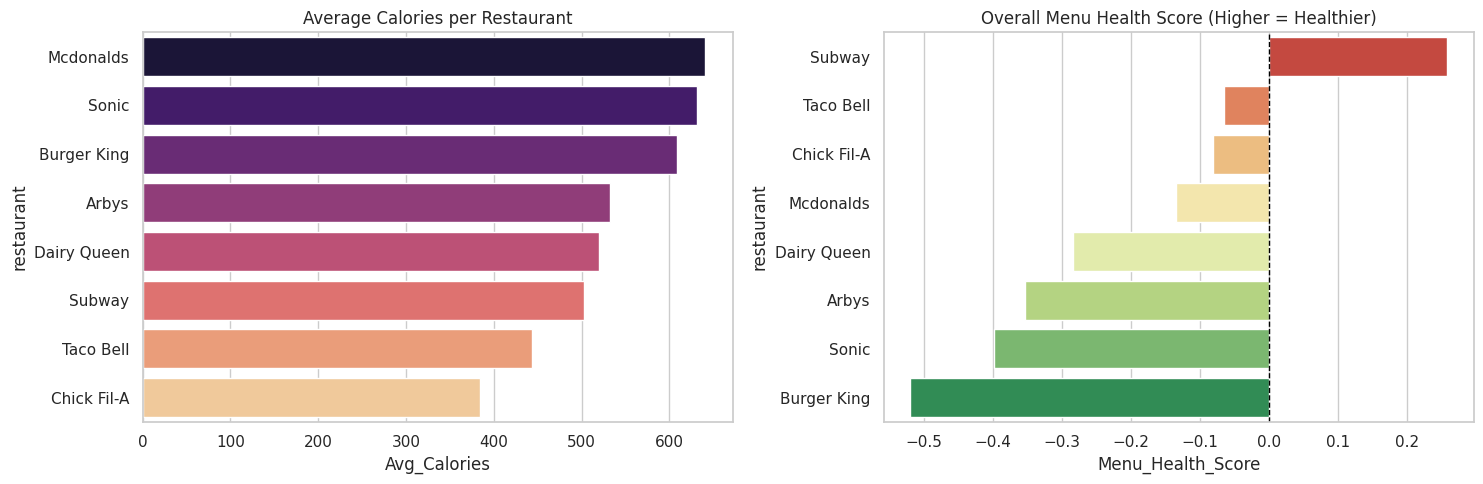

In [3]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('fastfood.csv')

# 1. Restaurant with Highest Number of Food Items
item_counts = df['restaurant'].value_counts().reset_index()
item_counts.columns = ['Restaurant', 'Item_Count']
print(f"=== Q1: Highest Menu Count -> {item_counts.iloc[0]['Restaurant']} ({item_counts.iloc[0]['Item_Count']} items) ===")
display(item_counts)

# 2. Top 10 Food Items with Highest Calories
top_10_calories = df[['restaurant', 'item', 'calories']].sort_values(by='calories', ascending=False).head(10)
print("\n=== Q2: Top 10 Highest Calorie Items ===")
display(top_10_calories)

# 3. Average Calorie Count per Restaurant
avg_calories = (
    df.groupby('restaurant', as_index=False)['calories'].mean()
    .rename(columns={'calories': 'Avg_Calories'})
    .sort_values(by='Avg_Calories', ascending=False)
)
print("\n=== Q3: Average Calories per Restaurant ===")
display(avg_calories)

# 4. Restaurant with Highest Average Protein Content
avg_protein = (
    df.groupby('restaurant', as_index=False)['protein'].mean()
    .rename(columns={'protein': 'Avg_Protein_g'})
    .sort_values(by='Avg_Protein_g', ascending=False)
)
print(f"\n=== Q4: Highest Avg Protein -> {avg_protein.iloc[0]['restaurant']} ({avg_protein.iloc[0]['Avg_Protein_g']:.2f}g) ===")
display(avg_protein)

# 5. Restaurant with Highest and Lowest Average Total Fat
avg_fat = (
    df.groupby('restaurant', as_index=False)['total_fat'].mean()
    .rename(columns={'total_fat': 'Avg_Total_Fat_g'})
    .sort_values(by='Avg_Total_Fat_g', ascending=False)
)
print(f"\n=== Q5: Highest Avg Fat -> {avg_fat.iloc[0]['restaurant']} ({avg_fat.iloc[0]['Avg_Total_Fat_g']:.2f}g) | Lowest -> {avg_fat.iloc[-1]['restaurant']} ({avg_fat.iloc[-1]['Avg_Total_Fat_g']:.2f}g) ===")
display(avg_fat)

# 6. Food Items with Highest Sugar & Their Calories
top_sugar = df[['restaurant', 'item', 'sugar', 'calories']].sort_values(by='sugar', ascending=False).head(10)
print("\n=== Q6: Top 10 Highest Sugar Items & Their Calories ===")
display(top_sugar)

# 7. Effect of Food Type (Salad vs Other) on Calories, Fat, Carbs, and Protein
salad_comp = df.groupby('salad', as_index=False)[['calories', 'total_fat', 'total_carb', 'protein']].mean()
print("\n=== Q7: Nutritional Averages by Food Type (Salad vs Other) ===")
display(salad_comp)

# 8. Restaurant Offering Best Combination of Low Calories & High Protein
df['protein_per_100_cal'] = (df['protein'] / df['calories']) * 100
best_protein_cal = (
    df.groupby('restaurant', as_index=False)['protein_per_100_cal'].mean()
    .rename(columns={'protein_per_100_cal': 'Avg_Protein_Per_100_Cal'})
    .sort_values(by='Avg_Protein_Per_100_Cal', ascending=False)
)
print(f"\n=== Q8: Best Low-Calorie High-Protein Ratio -> {best_protein_cal.iloc[0]['restaurant']} ===")
display(best_protein_cal)

# 9. Top 10 Least Healthy Food Items (Health Risk Score)
# Normalized (0-1) sum of: calories, total_fat, sat_fat, trans_fat, cholesterol, sodium
risk_cols = ['calories', 'total_fat', 'sat_fat', 'trans_fat', 'cholesterol', 'sodium']
risk_df = df.copy()
for col in risk_cols:
    risk_df[f'norm_{col}'] = (risk_df[col] - risk_df[col].min()) / (risk_df[col].max() - risk_df[col].min())

risk_df['Health_Risk_Score'] = risk_df[[f'norm_{col}' for col in risk_cols]].sum(axis=1)
least_healthy = risk_df[['restaurant', 'item', 'Health_Risk_Score'] + risk_cols].sort_values(by='Health_Risk_Score', ascending=False).head(10)
print("\n=== Q9: Top 10 Least Healthy Items (Highest Health Risk Score) ===")
display(least_healthy)

# 10. Healthiest Overall Restaurant Menu (Custom Menu Health Score)
# Positive nutrients (+): fiber, protein, vit_a, vit_c, calcium
# Negative nutrients (-): calories, total_fat, sugar, sodium
health_df = df.copy()
pos_cols = ['fiber', 'protein', 'vit_a', 'vit_c', 'calcium']
neg_cols = ['calories', 'total_fat', 'sugar', 'sodium']
health_df[pos_cols] = health_df[pos_cols].fillna(0)

for col in pos_cols + neg_cols:
    health_df[f'norm_{col}'] = (health_df[col] - health_df[col].min()) / (health_df[col].max() - health_df[col].min())

health_df['Menu_Health_Score'] = (
    health_df[[f'norm_{col}' for col in pos_cols]].sum(axis=1) -
    health_df[[f'norm_{col}' for col in neg_cols]].sum(axis=1)
)
healthiest_menu = (
    health_df.groupby('restaurant', as_index=False)['Menu_Health_Score'].mean()
    .sort_values(by='Menu_Health_Score', ascending=False)
)
print(f"\n=== Q10: Healthiest Overall Menu -> {healthiest_menu.iloc[0]['restaurant']} ===")
display(healthiest_menu)

# --- CHARTS FOR PPT ---
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=avg_calories, x='Avg_Calories', y='restaurant', ax=axes[0], hue='restaurant', palette='magma', legend=False)
axes[0].set_title('Average Calories per Restaurant')

sns.barplot(data=healthiest_menu, x='Menu_Health_Score', y='restaurant', ax=axes[1], hue='restaurant', palette='RdYlGn', legend=False)
axes[1].axvline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_title('Overall Menu Health Score (Higher = Healthier)')

plt.tight_layout()
plt.show()